In [28]:
import pandas as pd
import useful_rdkit_utils as uru
from rdkit import Chem
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from tqdm.auto import tqdm
import numpy as np
import seaborn as sns
from sklearn.manifold import TSNE
import mols2grid
import matplotlib.cm as cm

In [29]:
tqdm.pandas()

In [30]:
sns.set()
sns.set(rc={'figure.figsize': (10, 10)})
sns.set_style('whitegrid')
sns.set_context('talk')

In [31]:
smiles_url = "https://raw.githubusercontent.com/PatWalters/practical_cheminformatics_tutorials/main/data/cluster_test.smi"
df = pd.read_csv(smiles_url,sep=" ",names=["SMILES","Name"])

In [32]:
smi2fp = uru.Smi2Fp()
df['fp'] = df.SMILES.progress_apply(smi2fp.get_np)

  0%|          | 0/735 [00:00<?, ?it/s]

In [33]:
df

,SMILES,Name,fp
0,CCC(=O)/N=C1\S[C@H]2CS(=O)(=O)C[C@@H]2N1c1ccc(...,16741133,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,Cc1ccc(Cl)cc1N1/C(=N\C(=O)CCC(=O)O)S[C@H]2CS(=...,101303273,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CCCCC(=O)/N=C1/S[C@H]2CS(=O)(=O)C[C@@H]2N1c1cc...,32504126,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,CCN(CC)c1ccc(N2/C(=N\C(=O)CC#N)S[C@H]3CS(=O)(=...,101319242,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,CC[C@H](C)C(=O)/N=C1/S[C@H]2CS(=O)(=O)C[C@H]2N...,36638719,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
...,...,...,...
730,Cc1ccc(C)c(OCCNC(=O)CN(c2cccc([N+](=O)[O-])c2)...,223995643,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
731,CCOc1cccc(CNC(=O)[C@@H](C)N(c2cccc([N+](=O)[O-...,220419463,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
732,Cc1ccc(OCCNC(=O)CN(c2cccc([N+](=O)[O-])c2)S(C)...,223776199,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
733,COc1ccc(CN(C)C(=O)CN(c2cccc([N+](=O)[O-])c2)S(...,7871824,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [34]:
X = np.stack(df.fp)

In [35]:
num_clusters = 8
km = KMeans(n_clusters=num_clusters,random_state=42,n_init='auto')
km.fit(X)
cluster_list = km.predict(X)

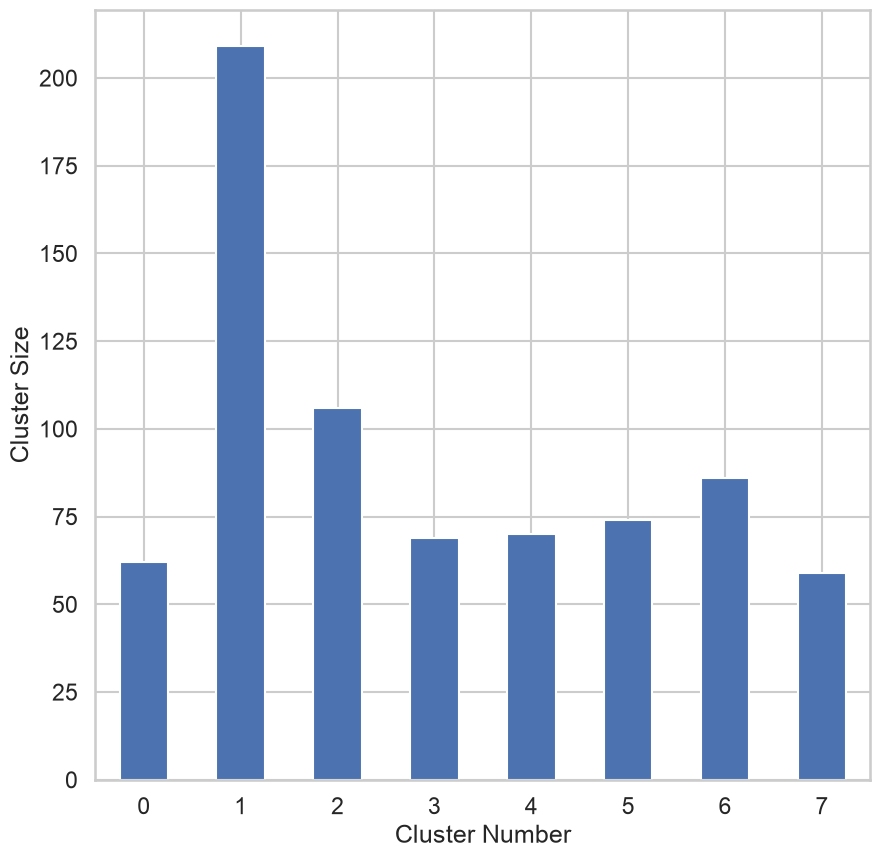

In [36]:
ax = pd.Series(cluster_list).value_counts().sort_index().plot(kind="bar")
ax.set_xlabel("Cluster Number")
ax.set_ylabel("Cluster Size")
ax.tick_params(axis='x', rotation=0)

In [37]:
cluster_range = range(5,25)
score_list = []
for k in tqdm(cluster_range):
    km = KMeans(n_clusters=k,random_state=42,n_init='auto')
    cluster_labels = km.fit_predict(X)
    score = silhouette_score(X,cluster_labels)
    score_list.append([k,score])

  0%|          | 0/20 [00:00<?, ?it/s]

In [38]:
score_df = pd.DataFrame(score_list,columns=["K","Silhouette Score"])
score_df.head()

,K,Silhouette Score
0,5,0.256244
1,6,0.202253
2,7,0.189455
3,8,0.272224
4,9,0.222486


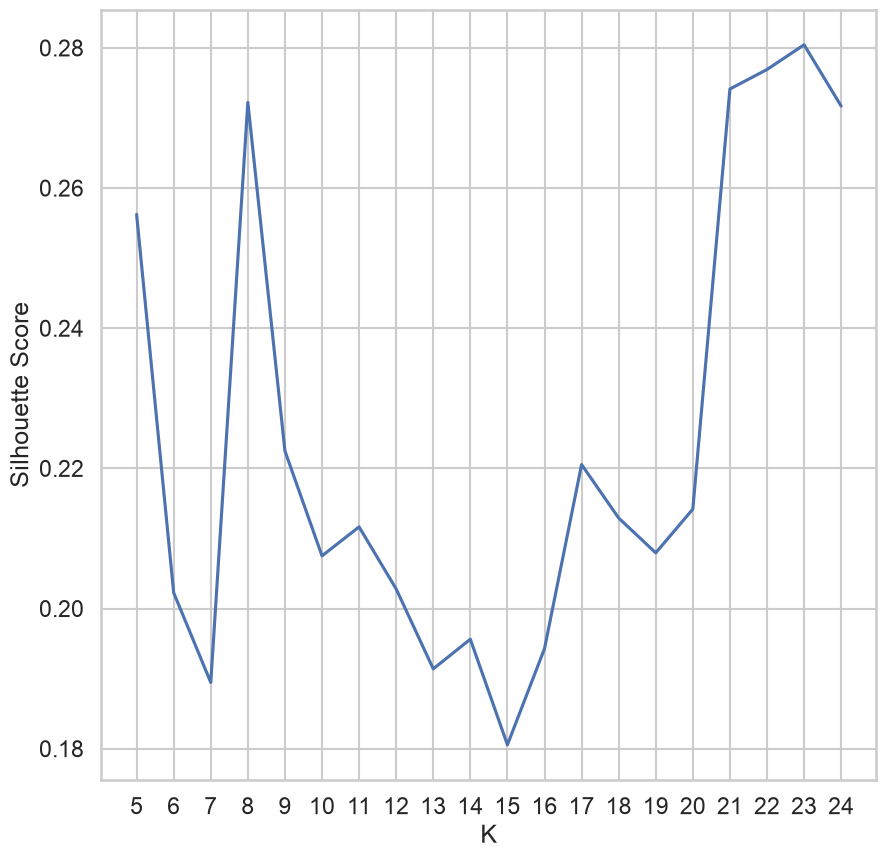

In [39]:
ax = sns.lineplot(x="K",y="Silhouette Score",data=score_df)
ax.set_xticks(cluster_range);

In [40]:
opt_num_clusters = score_df.sort_values("Silhouette Score").K.values[0]
print(f"In the figure above the minimum silhouette score is observed with {opt_num_clusters} clusters.  Let's run KMeans with num_clusters = {opt_num_clusters}.")

In the figure above the minimum silhouette score is observed with 15 clusters.  Let's run KMeans with num_clusters = 15.


In [41]:
num_clusters = opt_num_clusters
km_opt = KMeans(n_clusters=num_clusters, random_state=42, n_init="auto")
clusters_opt = km_opt.fit_predict(X)

In [42]:
def silhouette_plot(X,cluster_labels):
    """
    Adapted from https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
    """
    sns.set_style('whitegrid')
    sample_df = pd.DataFrame(silhouette_samples(X,cluster_labels),columns=["Silhouette"])
    sample_df['Cluster'] = cluster_labels
    n_clusters = max(cluster_labels+1)
    color_list = [cm.nipy_spectral(float(i) / n_clusters) for i in range(0,n_clusters)]
    ax = sns.scatterplot()
    ax.set_xlim([-0.1, 1])
    ax.set_ylim([0, len(X) + (n_clusters + 1) * 10])
    silhouette_avg = silhouette_score(X, cluster_labels)
    y_lower = 10
    unique_cluster_ids = sorted(sample_df.Cluster.unique())
    for i in unique_cluster_ids:
        cluster_df = sample_df.query('Cluster == @i')
        cluster_size = len(cluster_df)
        y_upper = y_lower + cluster_size
        ith_cluster_silhouette_values = cluster_df.sort_values("Silhouette").Silhouette.values
        color = color_list[i]
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                    0, ith_cluster_silhouette_values,
                    facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * cluster_size, str(i),fontsize="small")
        y_lower = y_upper + 10
    ax.axvline(silhouette_avg,color="red",ls="--")
    ax.set_xlabel("Silhouette Score")
    ax.set_ylabel("Cluster")
    ax.set(yticklabels=[]) 
    ax.yaxis.grid(False) 

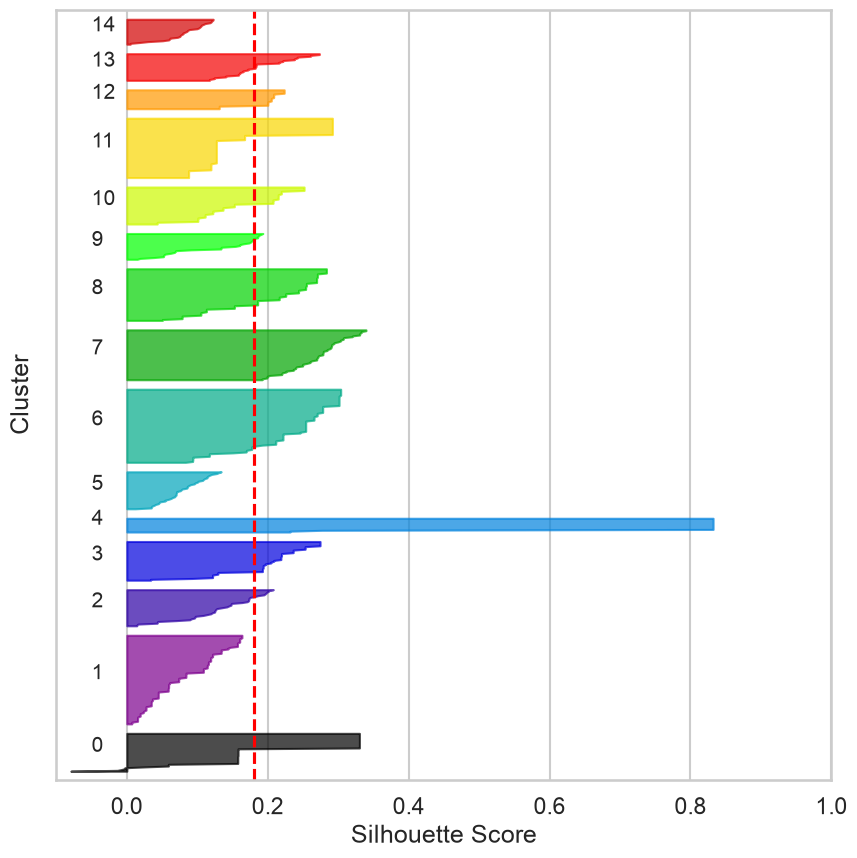

In [43]:
silhouette_plot(X,clusters_opt)

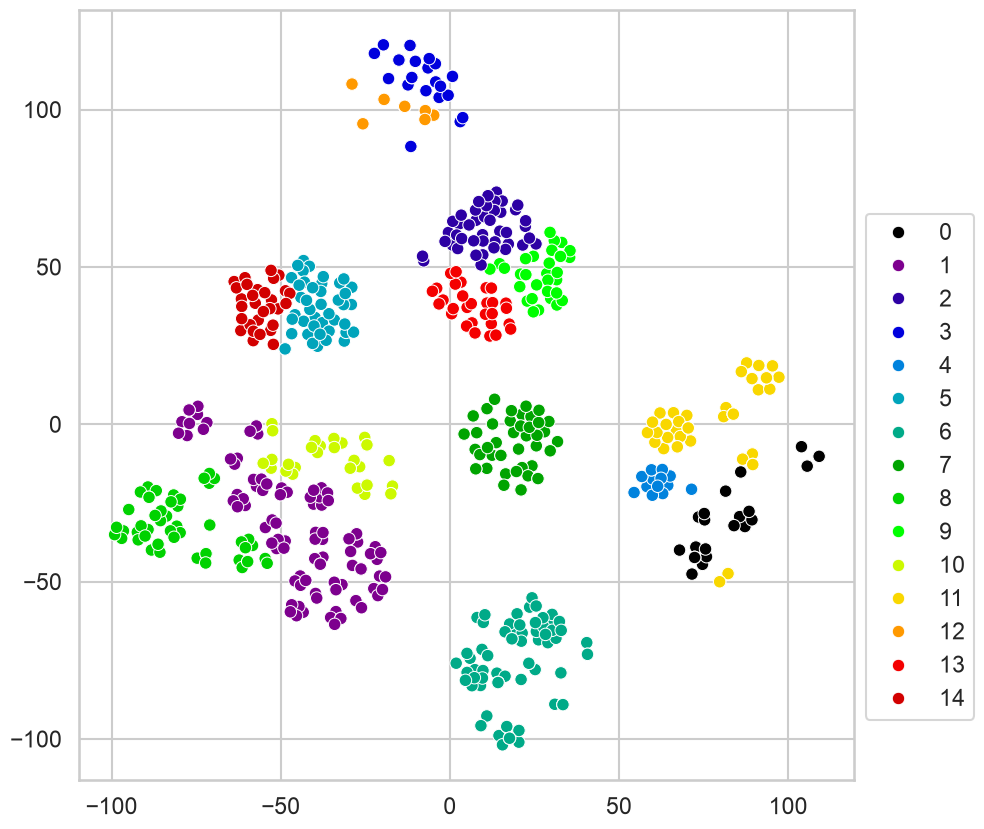

In [44]:
tsne = TSNE(n_components=2, init='pca',learning_rate='auto')
crds = tsne.fit_transform(X,clusters_opt)
color_list = [cm.nipy_spectral(float(i) / num_clusters) for i in range(0,num_clusters)]
ax = sns.scatterplot(x=crds[:,0],y=crds[:,1],hue=clusters_opt,palette=color_list,legend=True)
ax.legend(loc='upper left', bbox_to_anchor=(1.00, 0.75), ncol=1);

In [45]:
opt_cluster_df = df.copy()
opt_cluster_df['Cluster'] = clusters_opt

In [46]:
cluster_id = 1
cols = ["SMILES","Name","Cluster"]
display_df = opt_cluster_df[cols].query("Cluster == @cluster_id")
mols2grid.display(display_df,subset=["img"],n_cols=3,size=(320,240))

In [47]:
opt_cluster_df[["SMILES","Name","Cluster"]].to_csv("clusters.csv",index=False)